# Stock Market Prediction using LSTM

This notebook demonstrates how to predict stock market prices using Long Short-Term Memory (LSTM) networks, a type of recurrent neural network designed to capture patterns and dependencies in sequential data. Using historical stock market data from the Nairobi Securities Exchange (NSE) or another available source, the model is trained on past closing prices to learn trends and generate future price predictions. By analyzing time-series data, LSTM models can identify complex temporal relationships, making them well-suited for stock price forecasting and financial market analysis.


In [1]:
#mport Libraries and Load the Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [4]:
data = pd.read_csv('NSE_SCOM_Safaricom.csv')
data.head()

,Date,Open,High,Low,Close,Vol.,Change %
0,11-06-2012,3.40,3.45,3.35,3.40,3.24M,0.00%
1,12-06-2012,3.40,3.50,3.40,3.45,6.09M,1.47%
2,13-06-2012,3.45,3.45,3.35,3.40,7.29M,-1.45%
3,14-06-2012,3.40,3.45,3.35,3.40,31.81M,0.00%
4,15-06-2012,3.40,3.50,3.40,3.40,7.57M,0.00%


In [5]:
# Close price
data = data[['Close']]

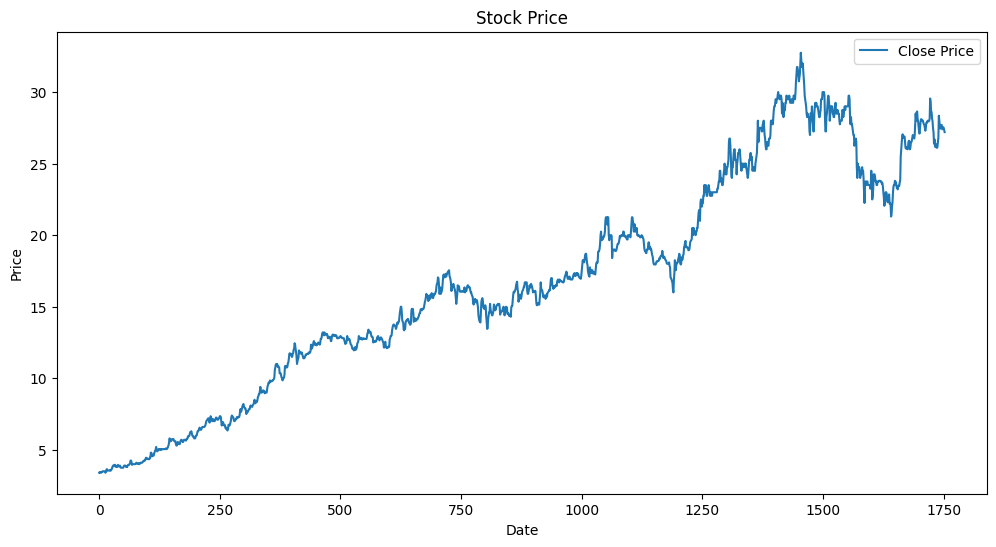

In [6]:
# Visualize the stock prices
plt.figure(figsize=(12, 6))
plt.plot(data['Close'], label='Close Price')
plt.title(f'Stock Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

In [7]:
# Normalize the stock prices using MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

In [8]:
# Prepare data for LSTM (using 60 timesteps to predict the next day's price)
X = []
y = []
for i in range(60, len(scaled_data)):
    X.append(scaled_data[i-60:i, 0])
    y.append(scaled_data[i, 0])

In [9]:
# Convert X and y to numpy arrays
X, y = np.array(X), np.array(y)

In [10]:
# Reshape X to be 3D for LSTM input: [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

Build and Train LSTM Model
Step 3: Build and Train the LSTM Model

In this step, we construct the LSTM model that will learn patterns from the historical stock price data. The model consists of two LSTM layers, which help capture both short-term and long-term dependencies in the time-series data. Dropout layers are added between the LSTM layers to reduce overfitting by randomly disabling a fraction of neurons during training. Finally, the model is compiled using the Adam optimizer, which efficiently updates the model's weights, and the Mean Squared Error (MSE) loss function, which measures the difference between the predicted and actual stock prices. Once compiled, the model is trained on the prepared dataset to learn the underlying trends and generate accurate stock price forecasts.

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [12]:
# Build the LSTM model
model = Sequential()

In [13]:
# First LSTM Layer with Dropout for regularization
model.add(LSTM(units=50, return_sequences=True, input_shape=(X.shape[1], 1)))
model.add(Dropout(0.2))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [14]:
# Second LSTM Layer with Dropout
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))

In [15]:
# Fully connected output layer
model.add(Dense(units=1))

In [16]:
# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [17]:
# Train the model
model.fit(X, y, epochs=10, batch_size=32)

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - loss: 0.0248
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0036
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.0034
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0031
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0027
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - loss: 0.0025
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0022
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0028
Epoch 9/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0023
Epoch 10/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - loss: 0.0026


Make Predictions and Visualize Results
Step 4: Make Predictions and Visualize Results

After training the LSTM model, the next step is to use it to predict stock prices on the test dataset, which consists of the most recent 100 days of stock market data that were not used during training. These predictions are then compared with the actual closing prices to evaluate the model's performance. By plotting both the predicted and actual stock prices on the same graph, we can visually assess how well the model captures market trends and fluctuations. This visualization provides valuable insights into the accuracy of the forecasts and helps identify areas where the model may perform well or require further improvement.

In [18]:
# Predict stock prices on the test set
test_data = data.tail(100)  # Using last 100 days for prediction
scaled_test_data = scaler.transform(test_data)

In [19]:
X_test = []
for i in range(60, len(scaled_test_data)):
    X_test.append(scaled_test_data[i-60:i, 0])

In [20]:
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

In [21]:
# Make predictions
predicted_prices = model.predict(X_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 275ms/step


In [22]:
# Invert scaling for actual prices
predicted_prices = scaler.inverse_transform(predicted_prices)

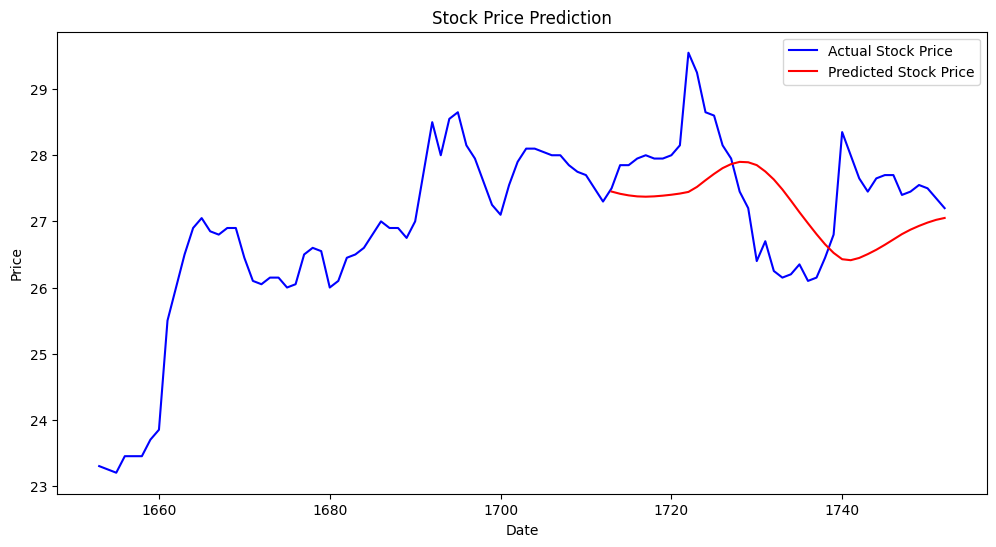

In [23]:
# Visualize the results
plt.figure(figsize=(12, 6))
plt.plot(data.index[-100:], test_data['Close'], color='blue', label='Actual Stock Price')
plt.plot(data.index[-40:], predicted_prices, color='red', label='Predicted Stock Price')
plt.title(f'Stock Price Prediction')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

### Model Evaluation

In [24]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(test_data['Close'][60:], predicted_prices))
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

Root Mean Squared Error (RMSE): 0.9490
